In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.


# GPS Positioning and Relativity

A GPS receiver finds *where it is* by finding *when it is*: every satellite broadcasts its
own clock time, the receiver measures how long the signal took to arrive, and multiplies by
the speed of light to get a **range**. Light covers ~30 cm per nanosecond, so the clocks
have to agree to **nanoseconds** — which is exactly why relativity here is a *practical
engineering* problem, not a curiosity. Get it wrong and the position is wrong.

## Why we need relativity

A satellite clock does **not** tick at the same rate as a clock on the ground, for two
relativistic reasons that pull in *opposite* directions:

**1. Gravitational time dilation — general relativity.** A clock deeper in a gravitational
potential well runs *slower*. The satellite sits ~20 200 km up, high in the well where
Earth's potential is weaker, so its clock runs **faster** than ours on the ground:

$$\Big(\tfrac{\Delta f}{f}\Big)_{\mathrm{GR}}=\frac{\Phi_\mathrm{sat}-\Phi_\mathrm{ground}}{c^2}
   =\frac{GM_\oplus}{c^2}\Big(\frac{1}{R_\oplus}-\frac{1}{r}\Big)>0
   \;\;\Rightarrow\;\; +45.9\ \mu\mathrm{s/day}.$$

**2. Velocity time dilation — special relativity.** A *moving* clock runs slower. The
satellite races along at $v\approx 3.9$ km/s, so its clock runs **slower**:

$$\Big(\tfrac{\Delta f}{f}\Big)_{\mathrm{SR}}=-\frac{v^2}{2c^2}<0
   \;\;\Rightarrow\;\; -7.2\ \mu\mathrm{s/day}.$$

General relativity wins, so the **net is +38.6 µs/day fast**. Times $c$, that is
$\approx$ **11.6 km/day** of range error — GPS would drift uselessly within minutes. Each
satellite clock is therefore tuned to tick *slow* by this amount before launch (the
"factory offset"), cancelling the *average* effect.

**3. The eccentricity residual — what the receiver still must correct.** The factory offset
removes only the *mean* rate. Real orbits are slightly **eccentric**, so over each orbit the
altitude (potential) and speed *vary*, leaving a *periodic* relativistic term the receiver
applies per satellite:

$$\Delta t_\mathrm{rel}(t)=-\frac{2\,\mathbf{r}\cdot\mathbf{v}}{c^2}=F\,e\,\sqrt{a}\,\sin E(t),
  \qquad F=-\frac{2\sqrt{\mu}}{c^2}\approx-4.443\times10^{-10}\ \mathrm{s}/\sqrt{\mathrm m}.$$

It reaches ~±15 m per satellite — **this** is the correction we toggle on and off below.

## The estimator, and what every symbol is for

We solve for **position and clock together** with an EKF (`kalman.apps.gps.GPSModel`). Why
the clock? A receiver's cheap quartz oscillator is unsynchronised to GPS time, so its offset
is unknown — which is why you need **4** satellites (3 for position + 1 for the clock). The
measurement is a *pseudo*range — "pseudo" because it is the true geometric range **plus**
the receiver's own clock offset (and the relativity term):

$$\rho_i(t)=\underbrace{\lVert \mathbf{s}_i(t)-\mathbf{p}\rVert}_{\text{geometric range}}
            \;+\;b\;+\;\underbrace{c\,\Delta t_{\mathrm{rel},i}(t)}_{\text{relativity}}\;+\;\varepsilon_i .$$

| symbol | meaning | what it is used for |
|---|---|---|
| $\mathbf{p}=[x,y,z]$ | receiver position, ECEF [m] | the quantity we want |
| $b$ | clock bias $=c\,\delta t_\mathrm{rx}$ [m] | unknown receiver-clock offset (estimated) |
| $\dot b$ | clock drift [m/s] | rate of $b$ — **absorbs the +38.6 µs/day secular rate** |
| $\mathbf{s}_i(t)$ | satellite $i$ position [m] | from its Kepler orbit |
| $\rho_i$ | pseudorange to satellite $i$ [m] | the measurement fed to the filter |
| $c$ | speed of light | converts time ↔ range |
| $\mu=GM_\oplus$ | Earth's gravitational parameter | sets orbital speed **and** the potential |
| $a,\ e$ | orbit semi-major axis / eccentricity | geometry; $e$ sets the relativistic amplitude |
| $E(t)$ | eccentric anomaly | *where* the satellite is along its orbit |
| $F=-2\sqrt{\mu}/c^2$ | the GPS relativistic constant | scale of $\Delta t_\mathrm{rel}$ |

State $x=[x,y,z,b,\dot b]$: the dynamics are **linear** (a static receiver with a drifting
clock); only the pseudorange is **nonlinear** (range → an analytic line-of-sight Jacobian).
Toggling `model.apply_relativistic` decides whether the receiver subtracts the relativistic
terms — a clean **before / after**.

## 1 — The receiver, its sky, and the pseudoranges

We place a mid-latitude receiver and keep the 8 highest satellites above the horizon.
Their Keplerian motion drives both the geometry and the relativistic terms.

8 satellites, elevations [deg]: [77.4 52.4 41.4 27.3 17.9 16.3 13.3  7. ]
pseudoranges: (1800, 8)  mean range ~ 22821 km


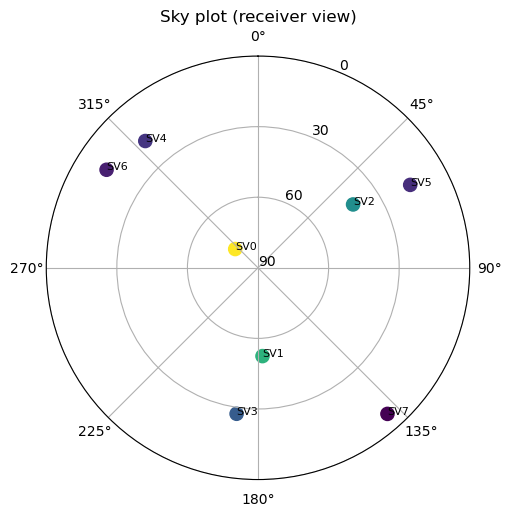

In [2]:
from kalman.apps.gps import GPSModel

gps = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, n_sat=8,
               fs=1.0, pseudorange_uncertainty=1.0)
az, el = gps.azel(0.0)
print(f"{gps.m} satellites, elevations [deg]: {np.round(el, 1)}")

chrono.restart()
pseudoranges = gps.simulate(1800.0, seed=0)     # 30 min @ 1 Hz, relativity baked in
chrono.lap("simulated pseudoranges")
print("pseudoranges:", pseudoranges.shape, " mean range ~", round(pseudoranges.mean()/1e3), "km")

# Sky plot (azimuth/elevation)
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.scatter(np.radians(az), 90 - el, s=90, c=el, cmap="viridis")
for i, (a, e) in enumerate(zip(az, el)):
    ax.annotate(f"SV{i}", (np.radians(a), 90 - e), fontsize=8)
ax.set_rmax(90); ax.set_rticks([0, 30, 60, 90]); ax.set_yticklabels(["90", "60", "30", "0"])
ax.set_title("Sky plot (receiver view)")
plt.show()

## 2 — Before / after the relativistic correction

We filter the **same** pseudoranges twice — once removing the relativistic terms
(`apply_relativistic = True`) and once not — starting both from the same ~50 m off guess.

position RMSE (after convergence):
  GR-corrected :   0.50 m
  uncorrected  :  16.57 m


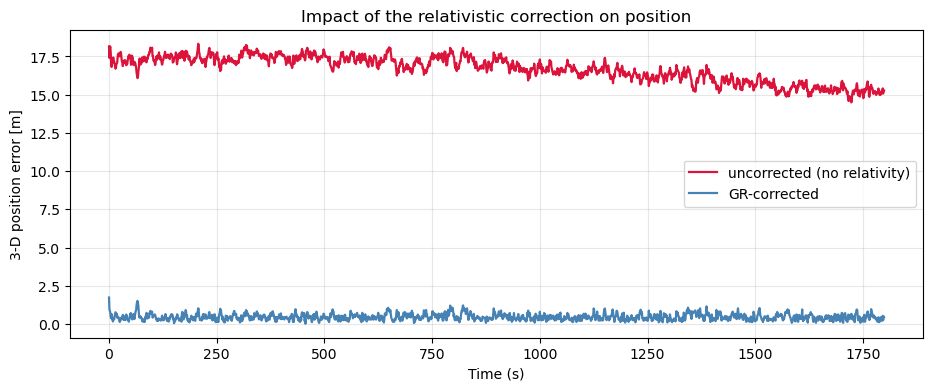

In [3]:
guess = np.concatenate([gps.receiver_ecef + [40.0, -30.0, 20.0], [0.0, 0.0]])

gps.apply_relativistic = True
gps.initial_state(guess)
rec_corr = gps.filter(pseudoranges)

gps.apply_relativistic = False
gps.initial_state(guess)
rec_unc = gps.filter(pseudoranges)

t = rec_corr.time
err_corr = gps.position_error(rec_corr)
err_unc = gps.position_error(rec_unc)
print(f"position RMSE (after convergence):")
print(f"  GR-corrected : {np.sqrt(np.mean(err_corr[300:]**2)):6.2f} m")
print(f"  uncorrected  : {np.sqrt(np.mean(err_unc[300:]**2)):6.2f} m")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, err_unc, color="crimson", lw=1.6, label="uncorrected (no relativity)")
ax.plot(t, err_corr, color="steelblue", lw=1.6, label="GR-corrected")
ax.set_xlabel("Time (s)"); ax.set_ylabel("3-D position error [m]")
ax.legend(); ax.grid(alpha=0.3); ax.set_title("Impact of the relativistic correction on position")
plt.show()

The corrected solution sits at the metre level; the uncorrected one carries a persistent
**~15 m bias** from the per-satellite eccentricity terms. Here is the model's signature
figure (East/North/Up error + the estimated clock) for the uncorrected run:

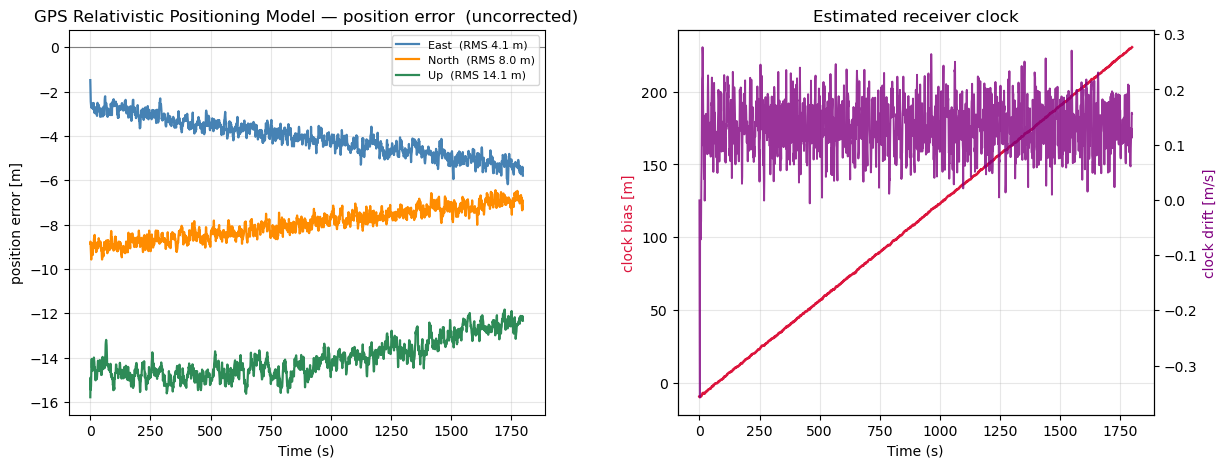

In [4]:
gps.apply_relativistic = False
gps.initial_state(guess)
rec = gps.filter(pseudoranges)
gps.plot(rec, sample=None)
plt.show()

## 3 — The clock absorbs the famous 38.6 µs/day

The big *secular* rate is **common to every satellite**, so it is indistinguishable from a
receiver-clock error and is swallowed by the estimated clock **drift** $\dot b$ — which is
exactly why a 4th satellite is needed (to solve for the clock). The filter literally
*measures* the relativistic rate: uncorrected, $\dot b$ converges to ~0.13 m/s ≈
38.6 µs/day; corrected, it sits near zero.

expected secular rate : 0.1339 m/s  =  +38.6 us/day  =  11.6 km/day
uncorrected  b_dot    : 0.1562 m/s  =  +45.0 us/day
GR-corrected b_dot    : 0.0223 m/s  =  +6.4 us/day


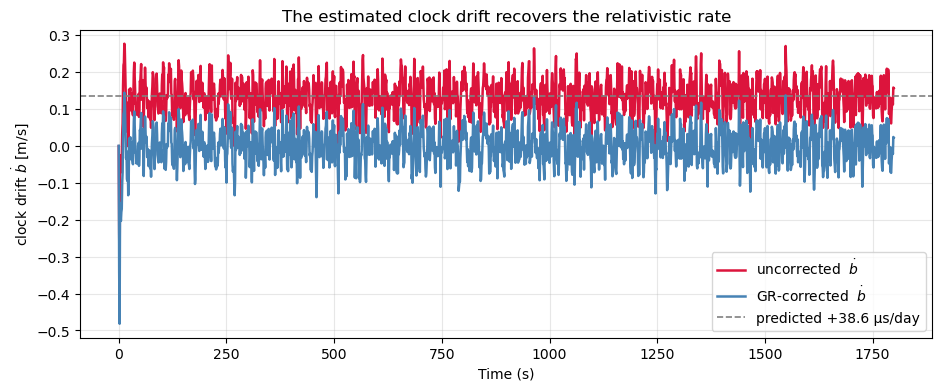

In [5]:
secular = 299792458.0 * 38.6e-6 / 86400.0   # 0.134 m/s
def us_per_day(v): return v / 299792458.0 * 86400.0 * 1e6

print(f"expected secular rate : {secular:.4f} m/s  =  +38.6 us/day  =  {secular*86.4:.1f} km/day")
print(f"uncorrected  b_dot    : {rec_unc.xk[-1,4]:.4f} m/s  =  {us_per_day(rec_unc.xk[-1,4]):+.1f} us/day")
print(f"GR-corrected b_dot    : {rec_corr.xk[-1,4]:.4f} m/s  =  {us_per_day(rec_corr.xk[-1,4]):+.1f} us/day")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, rec_unc.xk[:, 4], color="crimson", lw=1.8, label="uncorrected  $\dot b$")
ax.plot(t, rec_corr.xk[:, 4], color="steelblue", lw=1.8, label="GR-corrected  $\dot b$")
ax.axhline(secular, color="gray", ls="--", lw=1.2, label="predicted +38.6 µs/day")
ax.set_xlabel("Time (s)"); ax.set_ylabel("clock drift $\dot b$ [m/s]")
ax.legend(); ax.grid(alpha=0.3)
ax.set_title("The estimated clock drift recovers the relativistic rate")
plt.show()

## 4 — The per-satellite eccentricity correction

The part that actually corrupts **position** is the *differential*, per-satellite
eccentricity term $c\,\Delta t_\mathrm{rel}$ — it differs between satellites, so it cannot
be absorbed by the single clock state. Its amplitude is set by each orbit's eccentricity.

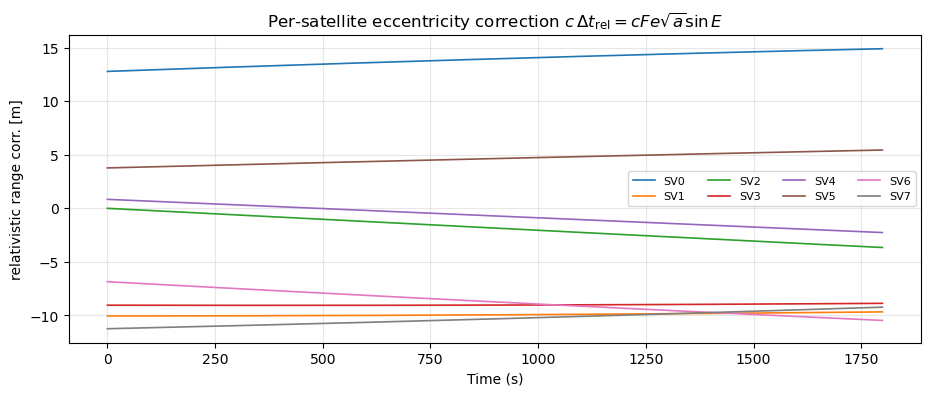

per-satellite correction magnitude: 2.3 - 14.9 m  (differential => ~17 m position bias)


In [6]:
ecc_corr = 299792458.0 * gps.constellation.relativistic_seconds(t)   # (N, M) metres
fig, ax = plt.subplots(figsize=(11, 4))
for i in range(gps.m):
    ax.plot(t, ecc_corr[:, i], lw=1.2, label=f"SV{i}")
ax.set_xlabel("Time (s)"); ax.set_ylabel("relativistic range corr. [m]")
ax.legend(fontsize=8, ncol=4); ax.grid(alpha=0.3)
ax.set_title(r"Per-satellite eccentricity correction $c\,\Delta t_\mathrm{rel}=cFe\sqrt{a}\sin E$")
plt.show()
mag = np.abs(ecc_corr).max(axis=0)
print(f"per-satellite correction magnitude: {mag.min():.1f} - {mag.max():.1f} m  (differential => ~{np.sqrt(np.mean(err_unc[300:]**2)):.0f} m position bias)")

## 5 — When satellites set: visibility and the user's real-world accuracy

So far the same 8 satellites stayed up the whole time. In reality the constellation **moves**: over
hours satellites **rise and set**, and a real sky is **partly blocked** — buildings, mountains, trees —
so only satellites above some **elevation mask** are usable. `GPSModel(..., elevation_mask=…)` tracks the
**full 24-satellite constellation** and, at every epoch, marks any satellite below the cutoff as **out
of sight**: its pseudorange becomes `NaN`, and the EKF's masked update simply **skips it** (when fewer
than 4 remain, the filter coasts open-loop on its dynamics — no position fix).

We fly **6 hours** over an **obstructed (urban-canyon) sky** — a 25° mask — and watch satellites come
and go, then read off the **precise impact on the user**.

24 satellites tracked;  in view: 2-6 (mean 4.5);  epochs with <4 (no fix): 58  (~29 min of 6 h)


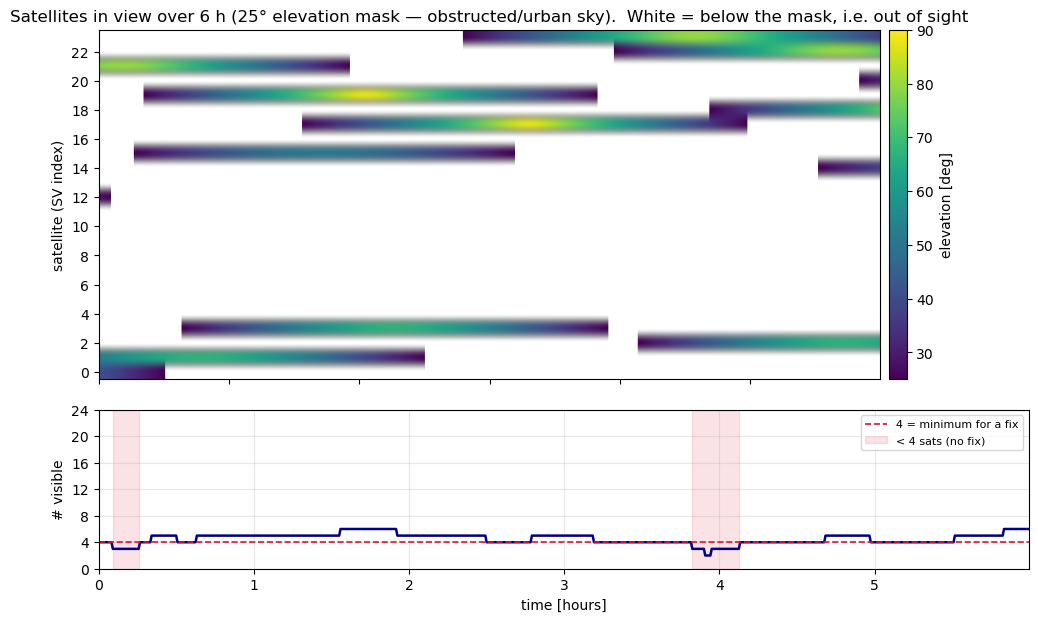

In [7]:
# Track the FULL constellation through an obstructed (urban-canyon) sky: a 25° elevation mask.
gps2 = GPSModel("rx", receiver_lat=45.0, receiver_lon=10.0, fs=1/30.0,
                pseudorange_uncertainty=1.0, elevation_mask=25.0)
DUR = 6 * 3600.0                                 # 6 hours
t   = np.arange(int(DUR * gps2.fs)) / gps2.fs
th  = t / 3600.0                                 # hours, for the x-axis
az, el = gps2.azel_track(t)                       # (N, M) az/el of every satellite over time
vis = gps2.visible_mask(t)                        # (N, M) above the mask?
nv  = gps2.n_visible(t)                           # (N,)  how many are in view
print(f"{gps2.m} satellites tracked;  in view: {nv.min()}-{nv.max()} (mean {nv.mean():.1f});  "
      f"epochs with <4 (no fix): {int((nv<4).sum())}  (~{(nv<4).sum()/gps2.fs/60:.0f} min of 6 h)")

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                             gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.12))
elm = np.where(vis, el, np.nan).T                 # elevation where visible, else blank
im = a0.imshow(elm, aspect="auto", origin="lower", extent=[th[0], th[-1], -0.5, gps2.m - 0.5],
               cmap="viridis", vmin=25, vmax=90)
a0.set_ylabel("satellite (SV index)"); a0.set_yticks(range(0, gps2.m, 2))
a0.set_title("Satellites in view over 6 h (25° elevation mask — obstructed/urban sky).  "
             "White = below the mask, i.e. out of sight")
fig.colorbar(im, ax=a0, pad=0.01).set_label("elevation [deg]")
a1.plot(th, nv, color="navy", lw=1.8)
a1.axhline(4, color="crimson", ls="--", lw=1.2, label="4 = minimum for a fix")
a1.fill_between(th, 0, 1, where=nv < 4, transform=a1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats (no fix)")
a1.set_ylabel("# visible"); a1.set_xlabel("time [hours]")
a1.set_ylim(0, gps2.m); a1.set_yticks(range(0, gps2.m + 1, 4))
a1.legend(fontsize=8, loc="upper right"); a1.grid(alpha=0.3)
plt.show()

### What it costs the user: geometry × ranging error

How good a fix is depends on **where** the visible satellites are, not just **how many**. Satellites
bunched together — or barely 4 in view — give a weak intersection of ranges, quantified by the
**dilution of precision (DOP)**. To first order the user's position error is

$$\sigma_\text{position} \;\approx\; \text{DOP}\times\sigma_\text{range},$$

so DOP **multiplies** every ranging error. When satellites set and the geometry thins, DOP spikes —
and with it the position error.

- The **snapshot** (single-epoch) user gets exactly $\text{HDOP}\cdot\sigma$: fine in open sky, but
  blowing up to **kilometres** when the geometry collapses, and **no fix at all** when fewer than 4
  satellites are visible.
- The **Kalman** user fuses over time and a near-static dynamics model, so it **rides through** the
  bad-geometry windows at the metre level — *provided the ranging error itself is small*, which is
  exactly what the **relativistic correction** buys. Without it, the same user carries a persistent
  ~15–20 m bias no matter how good the geometry.

Geometry **and** relativity both decide the user's real-world accuracy.

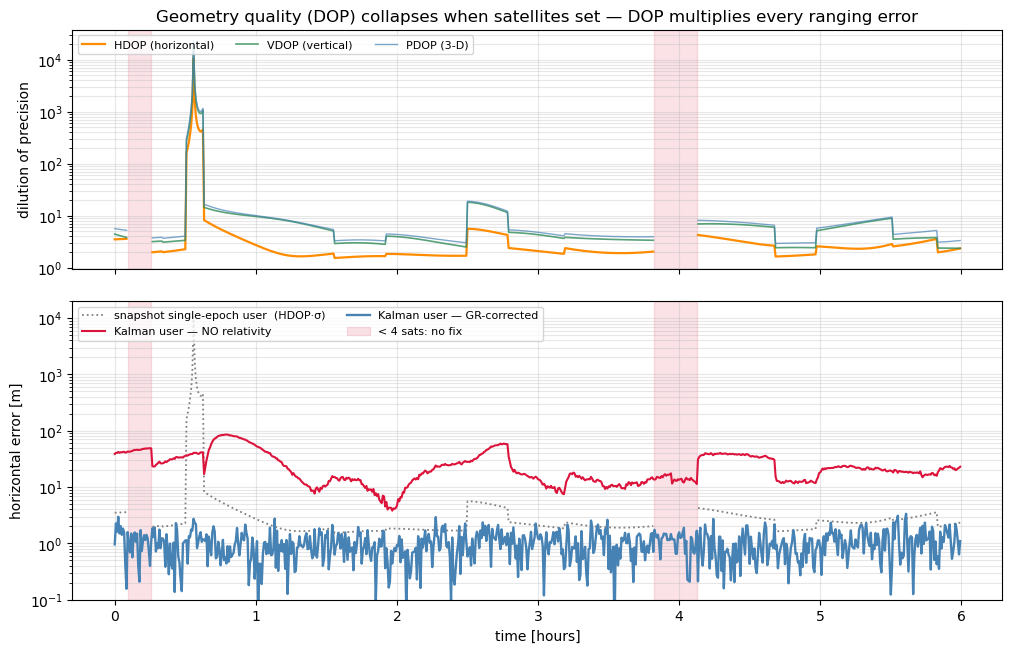

snapshot single-epoch user : median 2.2 m, worst 10619 m
Kalman user, GR-corrected  : median 0.98 m   (rides through the bad geometry)
Kalman user, no relativity : median 19.0 m   (persistent relativistic bias)


In [8]:
D = gps2.dop(t)                                  # geometry quality of the *visible* satellites
hdop, vdop, pdop = D["hdop"], D["vdop"], D["pdop"]

# Same sky, filtered twice: with and without the relativistic correction.
pr2   = gps2.simulate(DUR, seed=0)               # out-of-sight satellites come back as NaN
guess = np.concatenate([gps2.receiver_ecef + [40., -30., 20.], [0., 0.]])
gps2.apply_relativistic = True;  gps2.initial_state(guess); rec_c = gps2.filter(pr2)
gps2.apply_relativistic = False; gps2.initial_state(guess); rec_u = gps2.filter(pr2)
hc = np.hypot(*gps2.enu_error(rec_c)[:, :2].T)   # horizontal error, GR-corrected
hu = np.hypot(*gps2.enu_error(rec_u)[:, :2].T)   # horizontal error, no relativity
snap = hdop * gps2._sigma_rho                    # snapshot single-epoch horizontal 1σ = HDOP·σ
outage = nv < 4

fig, (b0, b1) = plt.subplots(2, 1, figsize=(12, 7.4), sharex=True,
                             gridspec_kw=dict(height_ratios=[1, 1.25], hspace=0.12))
b0.semilogy(th, hdop, color="darkorange", lw=1.6, label="HDOP (horizontal)")
b0.semilogy(th, vdop, color="seagreen",  lw=1.2, alpha=0.8, label="VDOP (vertical)")
b0.semilogy(th, pdop, color="steelblue", lw=1.0, alpha=0.7, label="PDOP (3-D)")
b0.fill_between(th, 0, 1, where=outage, transform=b0.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid")
b0.set_ylabel("dilution of precision"); b0.grid(alpha=0.3, which="both")
b0.legend(fontsize=8, ncol=3, loc="upper left")
b0.set_title("Geometry quality (DOP) collapses when satellites set — DOP multiplies every ranging error")

b1.semilogy(th, np.clip(snap, 1e-2, None), color="0.5", lw=1.3, ls=":",
            label="snapshot single-epoch user  (HDOP·σ)")
b1.semilogy(th, np.clip(hu, 1e-2, None), color="crimson", lw=1.5, label="Kalman user — NO relativity")
b1.semilogy(th, np.clip(hc, 1e-2, None), color="steelblue", lw=1.7, label="Kalman user — GR-corrected")
b1.fill_between(th, 0, 1, where=outage, transform=b1.get_xaxis_transform(),
                color="crimson", alpha=0.12, step="mid", label="< 4 sats: no fix")
b1.set_ylabel("horizontal error [m]"); b1.set_xlabel("time [hours]")
b1.set_ylim(0.1, 2e4); b1.grid(alpha=0.3, which="both")
b1.legend(fontsize=8, ncol=2, loc="upper left")
plt.show()

print(f"snapshot single-epoch user : median {np.nanmedian(snap):.1f} m, worst {np.nanmax(snap):.0f} m")
print(f"Kalman user, GR-corrected  : median {np.median(hc[20:]):.2f} m   (rides through the bad geometry)")
print(f"Kalman user, no relativity : median {np.median(hu[20:]):.1f} m   (persistent relativistic bias)")

## Takeaways

- GPS positioning is an **EKF** over $[x,y,z,b,\dot b]$ with nonlinear pseudorange
  measurements — the framework handles it with an analytic line-of-sight Jacobian.
- The **net +38.6 µs/day** relativistic rate (SR −7.2, GR +45.9) is *common-mode* and is
  absorbed by the estimated clock drift — the filter recovers it to within a µs/day.
- The **per-satellite eccentricity** correction $cFe\sqrt a\sin E$ is what genuinely biases
  position; removing it takes the solution from a ~15 m bias to the metre level.
- This is why every GPS receiver applies the relativistic clock correction: without general
  relativity, GPS would be wrong by tens of metres (and the clock by kilometres per day).
- **Satellites rise and set.** Over hours the visible set changes; in an obstructed sky some drop
  **out of sight**, and when fewer than 4 remain there is **no fix**. An `elevation_mask` makes the EKF
  skip out-of-sight satellites (NaN-masked update).
- **DOP approximately multiplies the ranging error** ($\sigma_\text{position}\approx\mathrm{DOP}\times\sigma_\text{range}$, to first order). A single-epoch user in poor geometry can momentarily be off by **kilometres** — yet the Kalman filter rides through at the **metre** level, *because* the relativistic correction keeps the underlying ranging error small. The user's real-world accuracy is set by **geometry and relativity together**.